# TOPIK 07 · Irigasi Pintar Berbasis IoT
**Tujuan:** setiap jam, untuk setiap petak, tentukan **perlu disiram sekarang (1) atau tidak (0)**, meniru keputusan agronom.


| Bagian | Isi | Hari |
|---|---|---|
| 1–3 | Memuat dan **memeriksa** data | 1 |
| 4 | **Membersihkan** data | 1 |
| 5–6 | Membuat fitur dan **membagi data berdasarkan waktu** | 1 |
| 7 | **Baseline** wajib (kelembapan < 35) | 1 |
| 8–10 | Melatih model, memilih threshold, membahas biaya kesalahan | 2 |
| 11 | Menyimpan model untuk aplikasi web | 2 |
| 12 | **Membuka data test (SATU KALI)** | 3 |


In [3]:
import pandas as pd                 # mengolah data tabel (DataFrame)
import numpy as np                  # operasi angka/array
import matplotlib.pyplot as plt     # membuat grafik
import joblib                       # menyimpan model ke file

from sklearn.compose import ColumnTransformer           # memproses kolom berbeda dengan cara berbeda
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline              # merangkai preprocessing + model
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 30)   # supaya semua kolom terlihat saat ditampilkan
BIRU, ORANYE, HIJAU = "#2a78d6", "#eb6834", "#1baf7a"   # warna grafik

## 2. Memuat data

In [4]:
df_raw = pd.read_csv("raw.csv")     # baca file CSV menjadi tabel
print("Ukuran data:", df_raw.shape) # (jumlah baris, jumlah kolom)
df_raw.head()                       # tampilkan 5 baris pertama

Ukuran data: (35452, 12)


,waktu,petak,tanaman,jenis_tanah,umur_tanaman_hari,kelembaban_tanah_pct,suhu_udara_C,kelembaban_udara_pct,cahaya_lux,curah_hujan_mm,prakiraan_hujan_6jam_mm,perlu_siram
0,2025-08-01 00:00,P01,cabai,lempung,24,56.9,16.6,93.0,0.0,0.0,0.0,0
1,2025-08-01 01:00,P01,cabai,lempung,24,56.8,16.9,99.0,0.0,0.0,0.0,0
2,2025-08-01 03:00,P01,cabai,lempung,24,57.5,17.3,84.0,0.0,0.0,0.0,0
3,2025-08-01 04:00,P01,cabai,lempung,24,57.4,16.8,91.0,0.0,0.0,0.9,0
4,2025-08-01 05:00,P01,cabai,lempung,24,57.2,17.4,92.0,0.0,0.0,0.9,0


In [5]:
df_raw.info()    # tipe data tiap kolom + berapa yang tidak kosong

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35452 entries, 0 to 35451
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   waktu                    35452 non-null  object 
 1   petak                    35452 non-null  object 
 2   tanaman                  35452 non-null  object 
 3   jenis_tanah              35452 non-null  object 
 4   umur_tanaman_hari        35452 non-null  int64  
 5   kelembaban_tanah_pct     35452 non-null  float64
 6   suhu_udara_C             34924 non-null  float64
 7   kelembaban_udara_pct     35452 non-null  float64
 8   cahaya_lux               35452 non-null  float64
 9   curah_hujan_mm           35452 non-null  float64
 10  prakiraan_hujan_6jam_mm  35098 non-null  float64
 11  perlu_siram              35452 non-null  int64  
dtypes: float64(6), int64(2), object(4)
memory usage: 3.2+ MB


In [6]:
df_raw.describe().T   # ringkasan statistik: rata-rata, min, max, kuartil (T = ditransposisi supaya mudah dibaca)

,count,mean,std,min,25%,50%,75%,max
umur_tanaman_hari,35452.0,70.824128,27.369192,13.0,48.0,71.0,94.0,128.0
kelembaban_tanah_pct,35452.0,47.058595,9.241379,0.0,40.8,46.8,52.7,127.5
suhu_udara_C,34924.0,19.304624,2.980971,13.7,16.9,18.1,21.9,27.5
kelembaban_udara_pct,35452.0,84.984796,9.674936,58.0,77.0,87.0,93.0,100.0
cahaya_lux,35452.0,19857.934390,25915.889338,-95001.0,0.0,0.0,39500.0,95000.0
curah_hujan_mm,35452.0,0.174842,0.946752,0.0,0.0,0.0,0.0,14.0
prakiraan_hujan_6jam_mm,35098.0,1.232455,2.782087,0.0,0.0,0.0,1.1,25.5
perlu_siram,35452.0,0.040139,0.196287,0.0,0.0,0.0,0.0,1.0


## 3. Memeriksa data (EDA, *Exploratory Data Analysis*)
Soal bilang data "belum diperiksa oleh siapa pun". Jadi kita cari masalahnya satu per satu.
Setiap temuan nanti masuk laporan.

### 3.1 Baris duplikat

In [7]:
n_dup = df_raw.duplicated().sum()                              # baris yang persis sama dengan baris lain
n_dup_kunci = df_raw.duplicated(["waktu", "petak"]).sum()      # petak yang sama tercatat 2x pada jam yang sama
print("Duplikat persis      :", n_dup)
print("Duplikat waktu+petak :", n_dup_kunci)

Duplikat persis      : 297
Duplikat waktu+petak : 297


**Temuan:** ada 297 baris dobel. Isinya identik, jadi aman dihapus.

### 3.2 Penulisan kategori `tanaman` tidak konsisten

In [8]:
df_raw["tanaman"].value_counts()

,count
tanaman,
cabai,12895
selada,10761
tomat,10733
Tomat,178
Selada,165
lettuce,159
tomat,155
Cabai,141
cabe,139


**Temuan:** `Cabai`, `CABAI`, `cabe` → seharusnya `cabai`; `Tomat`, `tomat ` (ada spasi) → `tomat`; `Selada`, `lettuce` → `selada`.
Kalau tidak dibereskan, model menganggap semuanya tanaman berbeda.

In [9]:
# Cek: apakah setiap petak selalu berisi tanaman & tanah yang sama? (setelah dirapikan)
tmp = df_raw["tanaman"].str.strip().str.lower().replace({"cabe": "cabai", "lettuce": "selada"})
print(pd.crosstab(df_raw["petak"], tmp))

tanaman  cabai  selada  tomat
petak                        
P01       2225       0      0
P02       2213       0      0
P03          0       0   2217
P04          0       0   2220
P05          0    2219      0
P06          0    2219      0
P07       2214       0      0
P08          0       0   2205
P09          0    2216      0
P10       2216       0      0
P11          0       0   2214
P12          0    2212      0
P13       2213       0      0
P14          0       0   2210
P15          0    2219      0
P16       2220       0      0


Setiap petak hanya punya satu jenis tanaman (dan satu jenis tanah). Berarti perapian kita benar.

### 3.3 Data kosong (*missing*)

In [10]:
df_raw.isna().sum()

,0
waktu,0
petak,0
tanaman,0
jenis_tanah,0
umur_tanaman_hari,0
kelembaban_tanah_pct,0
suhu_udara_C,528
kelembaban_udara_pct,0
cahaya_lux,0
curah_hujan_mm,0


**Temuan:** `suhu_udara_C` kosong 528 baris, `prakiraan_hujan_6jam_mm` kosong 354 baris.

### 3.4 Nilai yang mustahil

In [11]:
k = df_raw["kelembaban_tanah_pct"]
print("Kelembapan tanah <= 0  :", (k <= 0).sum())
print("Kelembapan tanah >= 100:", (k >= 100).sum(), "→ nilai unik:", sorted(k[k >= 100].unique()))
print("Kelembapan tanah normal: min", k[(k > 0) & (k < 100)].min(), "max", k[(k > 0) & (k < 100)].max())
print()
print("Cahaya negatif         :", (df_raw["cahaya_lux"] < 0).sum())

Kelembapan tanah <= 0  : 32
Kelembapan tanah >= 100: 74 → nilai unik: [np.float64(100.0), np.float64(127.5)]
Kelembapan tanah normal: min 21.6 max 70.0

Cahaya negatif         : 70


**Temuan:**
- Kelembapan tanah **0** dan **100 / 127,5** adalah *error* sensor. Nilai normal hanya sekitar 21–70%. Angka 127,5 khas sensor yang rusak atau terputus.
- Cahaya **negatif** itu mustahil (lux minimal 0).

### 3.5 Sensor macet (nilainya tidak berubah berjam-jam)

In [12]:
d = df_raw.drop_duplicates().copy()
d["waktu"] = pd.to_datetime(d["waktu"])
d = d.sort_values(["petak", "waktu"])

sama = d.groupby("petak")["kelembaban_tanah_pct"].diff().eq(0)   # True jika nilainya sama dengan jam sebelumnya
blok = (~sama).cumsum()                                           # beri nomor untuk tiap "rangkaian nilai sama"
panjang = sama.groupby(blok).transform("sum")                     # berapa jam berturut-turut nilainya sama
print("Rangkaian nilai sama terpanjang per petak:")
print(panjang.groupby(d["petak"]).max())

Rangkaian nilai sama terpanjang per petak:
petak
P01     3
P02     2
P03     3
P04     3
P05    46
P06     3
P07     3
P08     2
P09     3
P10     3
P11     3
P12     3
P13     3
P14     6
P15     4
P16     3
Name: kelembaban_tanah_pct, dtype: int64


**Temuan:** di petak lain nilai paling lama sama 2–6 jam (wajar). Tapi **P05 macet 47 jam** di angka 49,5 (mulai 14 September).
Tanah tidak mungkin tidak berubah sama sekali selama 2 hari, jadi sensornya macet.

### 3.6 Jam yang hilang

In [13]:
jam_seharusnya = len(pd.date_range("2025-08-01 00:00", "2025-10-31 23:00", freq="h"))
print("Jam seharusnya per petak:", jam_seharusnya)
print(d.groupby("petak")["waktu"].nunique())

Jam seharusnya per petak: 2208
petak
P01    2199
P02    2198
P03    2193
P04    2198
P05    2199
P06    2199
P07    2196
P08    2192
P09    2195
P10    2200
P11    2198
P12    2204
P13    2193
P14    2198
P15    2197
P16    2196
Name: waktu, dtype: int64


**Temuan:** setiap petak kehilangan sekitar 4–16 jam data (sensor tidak mengirim). Jumlahnya kecil, tapi ini berarti "1 baris sebelumnya" belum tentu "1 jam sebelumnya". Hal ini perlu diingat saat membuat fitur.

### 3.7 ⭐ Temuan penting #1: agronom tidak berjaga di malam hari
Klien sendiri bilang agronomnya "tidak bisa berjaga 24 jam". Kita lihat di data:

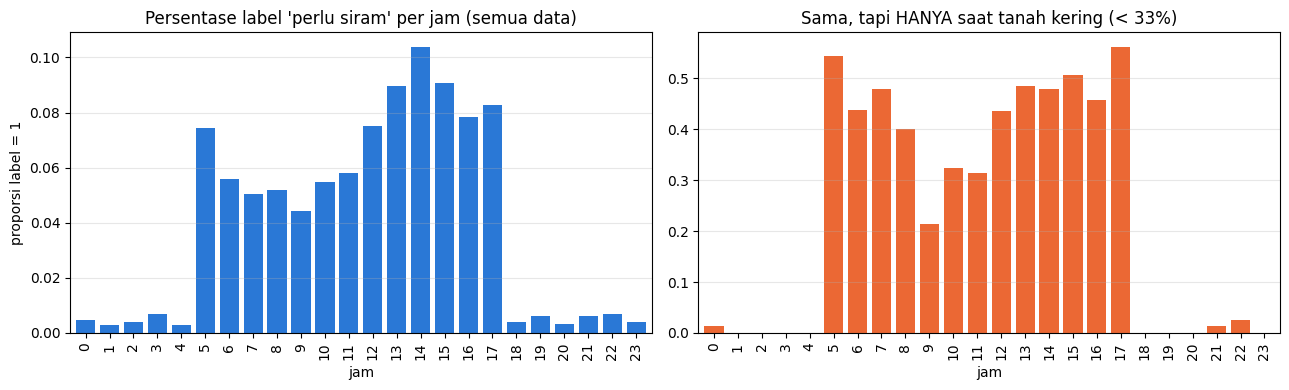

Kelembapan tanah rata-rata siang: 47.1 | malam: 46.8


In [14]:
d["jam"] = d["waktu"].dt.hour
k_ok = d["kelembaban_tanah_pct"].between(1, 99)
kering = d[k_ok & (d["kelembaban_tanah_pct"] < 33)]     # petak yang jelas-jelas kering

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
d.groupby("jam")["perlu_siram"].mean().plot.bar(ax=ax[0], color=BIRU, width=0.8)
ax[0].set_title("Persentase label 'perlu siram' per jam (semua data)")
ax[0].set_ylabel("proporsi label = 1")
kering.groupby("jam")["perlu_siram"].mean().plot.bar(ax=ax[1], color=ORANYE, width=0.8)
ax[1].set_title("Sama, tapi HANYA saat tanah kering (< 33%)")
for a in ax: a.grid(axis="y", alpha=0.3); a.set_xlabel("jam")
plt.tight_layout(); plt.show()

print("Kelembapan tanah rata-rata siang:", d[k_ok & d.jam.between(5,17)].kelembaban_tanah_pct.mean().round(1),
      "| malam:", d[k_ok & ~d.jam.between(5,17)].kelembaban_tanah_pct.mean().round(1))

**Temuan:** label 1 hampir **hanya muncul jam 05:00–17:59**. Pada malam hari, tanah yang kering pun hampir selalu berlabel 0.
Padahal kelembapan tanah malam dan siang rata-ratanya sama.

**Artinya:** label 0 di malam hari **bukan** berarti "tidak perlu disiram". Artinya "**agronomnya tidak ada**".
Kalau model dilatih dengan data malam, ia akan belajar "malam = jangan siram". Itu kebalikan dari yang diminta klien,
karena klien justru butuh sistem untuk jam-jam saat agronom tidak ada.

**Keputusan:** model dilatih dan dinilai **hanya dengan data jam 05–17** (label yang bisa dipercaya).
Setelah jadi, model tetap dipakai 24 jam.

### 3.8 ⭐ Temuan penting #2: label "terlambat satu jam" saat penyiraman
Ada label 1 pada tanah yang sangat basah (> 50%). Aneh, kan? Kita lihat contohnya:

In [15]:
d["k_sebelumnya"] = d.groupby("petak")["kelembaban_tanah_pct"].shift(1)
d["label_sebelumnya"] = d.groupby("petak")["perlu_siram"].shift(1)
aneh = d[(d.perlu_siram == 1) & d.kelembaban_tanah_pct.between(50, 99)]
print("Jumlah label 1 dengan tanah > 50%:", len(aneh))
aneh[["waktu", "petak", "tanaman", "k_sebelumnya", "kelembaban_tanah_pct", "label_sebelumnya", "perlu_siram"]].head(8)

Jumlah label 1 dengan tanah > 50%: 377


,waktu,petak,tanaman,k_sebelumnya,kelembaban_tanah_pct,label_sebelumnya,perlu_siram
85,2025-08-04 14:00:00,P01,cabai,31.8,52.6,0.0,1
182,2025-08-08 15:00:00,P01,cabai,32.4,54.3,0.0,1
296,2025-08-13 09:00:00,P01,cabai,29.7,53.2,1.0,1
486,2025-08-21 06:00:00,P01,cabai,30.9,51.3,1.0,1
582,2025-08-25 06:00:00,P01,cabai,31.1,54.0,1.0,1
763,2025-09-01 15:00:00,P01,cabai,32.4,55.1,0.0,1
883,2025-09-06 14:00:00,P01,cabai,30.6,50.7,1.0,1
934,2025-09-08 17:00:00,P01,cabai,31.3,55.0,1.0,1


**Temuan:** pada baris-baris ini, satu jam sebelumnya tanah masih kering (sekitar 30%), lalu tiba-tiba melonjak ke sekitar 55%.
Berarti **penyiraman terjadi pada jam itu**, dan sensor sudah membaca tanah yang basah, tapi label "perlu siram" masih tercatat di jam itu.

**Keputusan pembersihan:** jika label = 1 **dan** kelembapan naik ≥ 10 poin dari jam sebelumnya **dan** jam sebelumnya kering (< 45%),
maka label 1 dipindah ke jam sebelumnya (saat tanah benar-benar kering) dan jam ini diberi label 0 (tanahnya sudah basah).
Aturan ini ditentukan dari pola data, bukan dari hasil model, dan diterapkan sama untuk semua bagian data.

## 4. Membersihkan data
Semua langkah pembersihan dikumpulkan dalam satu fungsi supaya rapi dan bisa dijelaskan.

In [16]:
def bersihkan(df):
    df = df.drop_duplicates().copy()                              # (1) hapus 297 baris dobel
    df["waktu"] = pd.to_datetime(df["waktu"])                     # teks → tipe tanggal
    df = df.sort_values(["petak", "waktu"]).reset_index(drop=True)

    # (2) rapikan nama tanaman
    df["tanaman"] = (df["tanaman"].str.strip().str.lower()
                     .replace({"cabe": "cabai", "lettuce": "selada"}))

    # (3) tandai pembacaan sensor kelembapan tanah yang rusak: 0, >=100, atau macet >= 6 jam
    k = df["kelembaban_tanah_pct"]
    rusak = (k <= 0) | (k >= 100)
    sama = df.groupby("petak")["kelembaban_tanah_pct"].diff().eq(0)
    panjang = sama.groupby((~sama).cumsum()).transform("sum")
    df["sensor_rusak"] = rusak | (panjang >= 6)

    # (4) cahaya negatif → dianggap kosong
    df.loc[df["cahaya_lux"] < 0, "cahaya_lux"] = np.nan

    # (5) isi data kosong dengan nilai TERAKHIR yang diketahui di petak yang sama (forward fill).
    #     Kenapa ffill dan bukan rata-rata atau interpolasi? Karena di dunia nyata kita hanya tahu masa lalu.
    #     Interpolasi memakai nilai masa depan = curang (kebocoran data / leakage).
    for kol in ["suhu_udara_C", "cahaya_lux", "prakiraan_hujan_6jam_mm"]:
        df[kol] = df.groupby("petak")[kol].ffill()
    df["kelembaban_tanah_pct"] = df["kelembaban_tanah_pct"].where(~df["sensor_rusak"])
    df["kelembaban_tanah_pct"] = df.groupby("petak")["kelembaban_tanah_pct"].ffill()

    # (6) perbaiki label yang terlambat 1 jam saat penyiraman (lihat 3.8)
    g = df.groupby("petak")
    k_prev = g["kelembaban_tanah_pct"].shift(1)
    petak_sama = df["petak"].eq(df["petak"].shift(1))
    jam_siram = ((df["perlu_siram"] == 1) & (df["kelembaban_tanah_pct"] - k_prev >= 10)
                 & (k_prev < 45) & petak_sama)
    idx = df.index[jam_siram]
    df.loc[idx, "perlu_siram"] = 0          # jam ini tanah sudah basah → tidak perlu siram
    df.loc[idx - 1, "perlu_siram"] = 1      # jam sebelumnya tanah kering → seharusnya siram
    print(f"Label penyiraman yang digeser: {len(idx)}")
    return df

df = bersihkan(df_raw)
print("Baris setelah bersih:", len(df), "| sensor rusak ditandai:", df["sensor_rusak"].sum())

Label penyiraman yang digeser: 363
Baris setelah bersih: 35155 | sensor rusak ditandai: 157


In [17]:
# Cek: setelah dibersihkan, label 1 seharusnya hampir tidak ada lagi di tanah > 50%
cek = df[~df.sensor_rusak]
print("Label 1 dengan tanah > 50%:", ((cek.perlu_siram == 1) & (cek.kelembaban_tanah_pct > 50)).sum())
print("Proporsi label 1 total   :", cek.perlu_siram.mean().round(3))

Label 1 dengan tanah > 50%: 59
Proporsi label 1 total   : 0.034


Sisa beberapa puluh label aneh dibiarkan saja. Itu *noise* (kesalahan pencatatan acak) yang tidak bisa dijelaskan dengan pola tertentu.

## 5. Membuat fitur (*feature engineering*)
Agronom tidak hanya melihat angka kelembapan saat ini, tapi juga **seberapa cepat tanah mengering**.
Jadi kita tambahkan:
- `turun_1j` = kelembapan sekarang − kelembapan 1 jam lalu
- `turun_3j` = kelembapan sekarang − kelembapan 3 jam lalu

Kedua fitur ini **hanya memakai masa lalu**, jadi bisa dihitung secara nyata setiap jam.

In [18]:
def buat_fitur(df):
    df = df.copy()
    # Ambil kelembapan 1 jam & 3 jam lalu berdasarkan WAKTU, bukan "baris sebelumnya",
    # supaya tetap benar walaupun ada jam yang hilang (lihat 3.6).
    for n in [1, 3]:
        lalu = df[["petak", "waktu", "kelembaban_tanah_pct"]].copy()
        lalu["waktu"] = lalu["waktu"] + pd.Timedelta(hours=n)    # nilai jam X dipakai sebagai "n jam lalu" untuk jam X+n
        lalu = lalu.rename(columns={"kelembaban_tanah_pct": f"k{n}"})
        df = df.merge(lalu, on=["petak", "waktu"], how="left")   # jam hilang → kosong (NaN)
    df["turun_1j"] = df["kelembaban_tanah_pct"] - df["k1"]
    df["turun_3j"] = df["kelembaban_tanah_pct"] - df["k3"]
    df["jam"] = df["waktu"].dt.hour
    df["jam_kerja"] = df["jam"].between(5, 17)    # jam agronom berjaga (lihat 3.7)
    return df.drop(columns=["k1", "k3"])

df = buat_fitur(df)
df[["waktu", "petak", "kelembaban_tanah_pct", "turun_1j", "turun_3j"]].head()

,waktu,petak,kelembaban_tanah_pct,turun_1j,turun_3j
0,2025-08-01 00:00:00,P01,56.9,NaN,NaN
1,2025-08-01 01:00:00,P01,56.8,-0.1,NaN
2,2025-08-01 03:00:00,P01,57.5,NaN,0.6
3,2025-08-01 04:00:00,P01,57.4,-0.1,0.6
4,2025-08-01 05:00:00,P01,57.2,-0.2,NaN


**Fitur yang dipakai model:**

In [19]:
FITUR_KATEGORI = ["tanaman", "jenis_tanah"]
FITUR_ANGKA = ["umur_tanaman_hari", "kelembaban_tanah_pct", "suhu_udara_C", "kelembaban_udara_pct",
               "cahaya_lux", "curah_hujan_mm", "prakiraan_hujan_6jam_mm", "turun_1j", "turun_3j"]
FITUR = FITUR_KATEGORI + FITUR_ANGKA
TARGET = "perlu_siram"

Kenapa `petak` dan `jam` **tidak** dipakai sebagai fitur?
- `petak`: kalau klien menambah petak P17, model tidak akan mengenalnya. Lebih baik model belajar dari *sifat* petaknya (tanaman, tanah).
- `jam`: model bisa "menghafal jadwal kerja agronom", bukan kondisi tanaman. Informasi siang/malam sudah terwakili oleh `cahaya_lux`.

## 6. Membagi data berdasarkan waktu
- **Train** Agustus–September → untuk belajar
- **Validation** 1–14 Oktober → untuk membandingkan model dan memilih setting (boleh dipakai berkali-kali)
- **Test** 15–31 Oktober → **disimpan, tidak disentuh** sampai Bagian 12

In [20]:
pakai = df[~df["sensor_rusak"] & df["jam_kerja"]].dropna(subset=FITUR)   # baris yang labelnya bisa dipercaya

train = pakai[pakai.waktu < "2025-10-01"]
val   = pakai[(pakai.waktu >= "2025-10-01") & (pakai.waktu < "2025-10-15")]
test  = pakai[pakai.waktu >= "2025-10-15"]          # ⚠️ JANGAN dipakai sebelum Bagian 12

for nama, bag in [("train", train), ("val", val), ("test", test)]:
    print(f"{nama:5s}: {len(bag):6d} baris | {bag.waktu.min().date()} s/d {bag.waktu.max().date()} | label 1 = {bag[TARGET].mean():.1%}")

train:  12449 baris | 2025-08-01 s/d 2025-09-30 | label 1 = 6.7%
val  :   2860 baris | 2025-10-01 s/d 2025-10-14 | label 1 = 4.2%
test :   3456 baris | 2025-10-15 s/d 2025-10-31 | label 1 = 4.1%


Perhatikan label 1 hanya sekitar 7%. Data seperti ini disebut **tidak seimbang** (*imbalanced*). Karena itulah metriknya F1, bukan akurasi.

## 7. Baseline wajib: siram jika kelembapan tanah < 35
Tanpa machine learning, cukup satu aturan `if`.

In [21]:
def nilai(nama, y_benar, y_tebak):
    p, r, f = precision_score(y_benar, y_tebak), recall_score(y_benar, y_tebak), f1_score(y_benar, y_tebak)
    print(f"{nama:38s}  F1 = {f:.3f}   Precision = {p:.3f}   Recall = {r:.3f}")
    return f

tebak_baseline = (val["kelembaban_tanah_pct"] < 35).astype(int)
f1_baseline = nilai("Baseline (kelembapan < 35)", val[TARGET], tebak_baseline)

Baseline (kelembapan < 35)              F1 = 0.346   Precision = 0.276   Recall = 0.463


### Kenapa baseline-nya jelek? Kita cari tahu

In [22]:
tmp = train.copy()
tmp["rentang_kelembapan"] = pd.cut(tmp["kelembaban_tanah_pct"], [0, 30, 33, 36, 40, 45, 100])
print("Proporsi label 1 per rentang kelembapan & tanaman:")
print(pd.crosstab(tmp["rentang_kelembapan"], tmp["tanaman"], values=tmp[TARGET], aggfunc="mean").round(2))

kering = tmp[tmp.kelembaban_tanah_pct < 33]
print("\nSaat tanah kering (<33%), proporsi label 1 menurut prakiraan hujan:")
print(kering.groupby(pd.cut(kering.prakiraan_hujan_6jam_mm, [-1, 0, 2, 5, 30]))[TARGET].mean().round(2))

Proporsi label 1 per rentang kelembapan & tanaman:
tanaman             cabai  selada  tomat
rentang_kelembapan                      
(0, 30]              0.72    1.00   1.00
(30, 33]             0.45    0.82   0.93
(33, 36]             0.00    0.48   0.75
(36, 40]             0.01    0.77   0.03
(40, 45]             0.01    0.24   0.01
(45, 100]            0.00    0.00   0.01

Saat tanah kering (<33%), proporsi label 1 menurut prakiraan hujan:
prakiraan_hujan_6jam_mm
(-1, 0]    0.65
(0, 2]     0.77
(2, 5]     0.22
(5, 30]    0.11
Name: perlu_siram, dtype: float64


/tmp/ipykernel_877/2195167854.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(kering.groupby(pd.cut(kering.prakiraan_hujan_6jam_mm, [-1, 0, 2, 5, 30]))[TARGET].mean().round(2))


**Penjelasan:**
1. **Batas tiap tanaman berbeda.** Agronom menyiram **selada** sudah sejak sekitar 40%, **tomat** sekitar 36%, sedangkan **cabai** baru di bawah sekitar 32%. Satu angka 35 untuk semua tanaman pasti salah di sebagian kasus.
2. **Baseline tidak tahu soal hujan.** Saat prakiraan hujan ≥ 2 mm, agronom hampir tidak pernah menyiram walaupun tanah kering, persis seperti permintaan klien.

### (Bonus) Baseline ke-2: aturan "pintar" buatan tangan
Supaya adil, kita juga coba aturan tanpa ML yang lebih cerdas: batas per tanaman + cek hujan.
Batasnya dicari **hanya dari data train**.

In [23]:
terbaik = (0, None)
for bc in range(30, 38):            # batas cabai
    for bt in range(32, 40):        # batas tomat
        for bs in range(36, 44):    # batas selada
            for bh in [1, 2, 3, 5, 99]:   # batas prakiraan hujan (99 = abaikan hujan)
                batas = train["tanaman"].map({"cabai": bc, "tomat": bt, "selada": bs})
                tebak = (train["kelembaban_tanah_pct"] < batas) & (train["prakiraan_hujan_6jam_mm"] < bh)
                f = f1_score(train[TARGET], tebak)
                if f > terbaik[0]:
                    terbaik = (f, dict(cabai=bc, tomat=bt, selada=bs, hujan=bh))
ATURAN = terbaik[1]
print("Aturan terbaik di train:", ATURAN)

batas_val = val["tanaman"].map(ATURAN)
tebak_aturan = ((val["kelembaban_tanah_pct"] < batas_val) & (val["prakiraan_hujan_6jam_mm"] < ATURAN["hujan"])).astype(int)
f1_aturan = nilai("Aturan pintar (per tanaman + hujan)", val[TARGET], tebak_aturan)

Aturan terbaik di train: {'cabai': 32, 'tomat': 36, 'selada': 42, 'hujan': 2}
Aturan pintar (per tanaman + hujan)     F1 = 0.822   Precision = 0.946   Recall = 0.727


## 8. Melatih model machine learning
Kita coba 3 model, dari yang paling sederhana:
1. **Logistic Regression**: menggambar satu "garis pemisah" lurus.
2. **Random Forest**: ratusan pohon keputusan (*if-else*) yang melakukan voting.
3. **Gradient Boosting**: pohon-pohon yang dibuat berurutan, setiap pohon memperbaiki kesalahan pohon sebelumnya.

`OneHotEncoder` mengubah teks (cabai/tomat/selada) menjadi kolom 0/1, karena model hanya mengerti angka.
`StandardScaler` menyamakan skala angka (lux puluhan ribu vs suhu belasan) supaya adil untuk Logistic Regression.

In [24]:
def buat_pipeline(model):
    pra = ColumnTransformer([
        ("kategori", OneHotEncoder(handle_unknown="ignore"), FITUR_KATEGORI),
        ("angka", StandardScaler(), FITUR_ANGKA),
    ])
    return make_pipeline(pra, model)

kandidat = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

hasil = {}
for nama, model in kandidat.items():
    pipe = buat_pipeline(model).fit(train[FITUR], train[TARGET])   # BELAJAR dari train
    prob = pipe.predict_proba(val[FITUR])[:, 1]                     # peluang "perlu siram" di val
    hasil[nama] = (pipe, prob)
    nilai(nama + " (threshold 0.5)", val[TARGET], (prob >= 0.5).astype(int))

Logistic Regression (threshold 0.5)     F1 = 0.405   Precision = 0.261   Recall = 0.909
Random Forest (threshold 0.5)           F1 = 0.803   Precision = 0.814   Recall = 0.793
Gradient Boosting (threshold 0.5)       F1 = 0.858   Precision = 0.959   Recall = 0.777


`class_weight="balanced"` membuat model lebih "peduli" pada kelas 1 yang jumlahnya sedikit.
Gradient Boosting tidak memakai setting ini, tapi tetap paling bagus.

## 9. Memilih threshold di data validation
Model mengeluarkan **peluang** (0–1). Secara default, peluang ≥ 0,5 → "siram". Tapi 0,5 belum tentu yang terbaik.
Kita coba berbagai threshold **di data validation** (bukan test!).

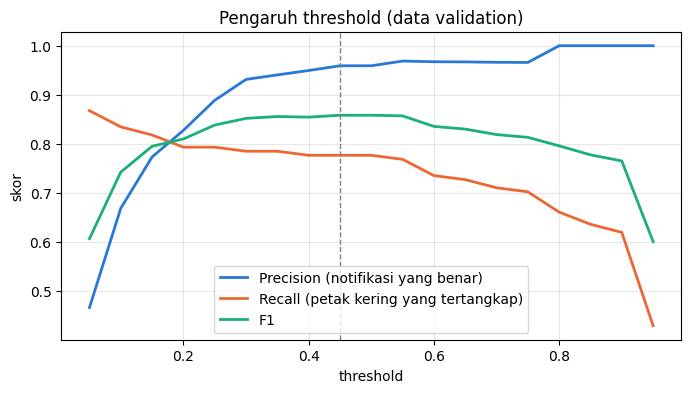

Threshold terbaik di val: 0.45 | F1 = 0.858


In [25]:
pipe_terbaik, prob_val = hasil["Gradient Boosting"]
thr_list = np.arange(0.05, 0.96, 0.05)
f1s = [f1_score(val[TARGET], prob_val >= t) for t in thr_list]
ps  = [precision_score(val[TARGET], prob_val >= t) for t in thr_list]
rs  = [recall_score(val[TARGET], prob_val >= t) for t in thr_list]
THRESHOLD = float(thr_list[int(np.argmax(f1s))])

plt.figure(figsize=(8, 4))
plt.plot(thr_list, ps, color=BIRU, lw=2, label="Precision (notifikasi yang benar)")
plt.plot(thr_list, rs, color=ORANYE, lw=2, label="Recall (petak kering yang tertangkap)")
plt.plot(thr_list, f1s, color=HIJAU, lw=2, label="F1")
plt.axvline(THRESHOLD, color="gray", ls="--", lw=1)
plt.xlabel("threshold"); plt.ylabel("skor"); plt.title("Pengaruh threshold (data validation)")
plt.legend(); plt.grid(alpha=0.3); plt.show()
print("Threshold terbaik di val:", round(THRESHOLD, 2), "| F1 =", round(max(f1s), 3))

**Cara membaca grafik:** threshold rendah → model gampang bilang "siram" → recall tinggi, tapi banyak notifikasi palsu (precision turun).
Threshold tinggi → sebaliknya. F1 adalah titik tengahnya.

## 10. Perbandingan akhir di validation & pertimbangan biaya

In [26]:
tebak_model = (prob_val >= THRESHOLD).astype(int)
print("=== Data VALIDATION (1–14 Okt, jam 05–17) ===")
nilai("Baseline (kelembapan < 35)", val[TARGET], tebak_baseline)
nilai("Aturan pintar", val[TARGET], tebak_aturan)
nilai(f"Gradient Boosting (thr={THRESHOLD:.2f})", val[TARGET], tebak_model)

=== Data VALIDATION (1–14 Okt, jam 05–17) ===
Baseline (kelembapan < 35)              F1 = 0.346   Precision = 0.276   Recall = 0.463
Aturan pintar                           F1 = 0.822   Precision = 0.946   Recall = 0.727
Gradient Boosting (thr=0.45)            F1 = 0.858   Precision = 0.959   Recall = 0.777


0.8584474885844748

In [27]:
def tampil_cm(nama, y, p):
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    print(f"{nama}")
    print(f"   Benar menyuruh siram (TP)          : {tp}")
    print(f"   Siram padahal tak perlu (FP) 💧🪣  : {fp}  → air terbuang / akar bisa busuk")
    print(f"   Telat/lupa siram (FN) 🥀           : {fn}  → tanaman stres")
    print(f"   Benar tidak menyuruh (TN)          : {tn}\n")

tampil_cm("BASELINE", val[TARGET], tebak_baseline)
tampil_cm("MODEL", val[TARGET], tebak_model)

BASELINE
   Benar menyuruh siram (TP)          : 56
   Siram padahal tak perlu (FP) 💧🪣  : 147  → air terbuang / akar bisa busuk
   Telat/lupa siram (FN) 🥀           : 65  → tanaman stres
   Benar tidak menyuruh (TN)          : 2592

MODEL
   Benar menyuruh siram (TP)          : 94
   Siram padahal tak perlu (FP) 💧🪣  : 4  → air terbuang / akar bisa busuk
   Telat/lupa siram (FN) 🥀           : 27  → tanaman stres
   Benar tidak menyuruh (TN)          : 2735



**Pembahasan biaya (tulis ulang dengan kata-katamu sendiri di laporan):**
- **False Negative (FN)** = petak perlu disiram tapi tidak ada notifikasi → tanaman stres, hasil panen turun. Satu jam terlambat biasanya belum fatal, karena notifikasi bisa muncul di jam berikutnya.
- **False Positive (FP)** = notifikasi siram padahal tidak perlu → air terbuang, dan kalau sering terjadi, akar membusuk. Selain itu, pengelola jadi **tidak percaya** pada notifikasi ("alarm palsu terus").
- Baseline punya **banyak FP**: ia menyuruh menyiram selada/cabai di saat yang salah dan saat akan hujan.
- Kalau klien lebih takut tanaman stres daripada membuang air, threshold bisa **diturunkan** (recall naik). Grafik di Bagian 9 menunjukkan konsekuensinya.

### Fitur apa yang paling berpengaruh?

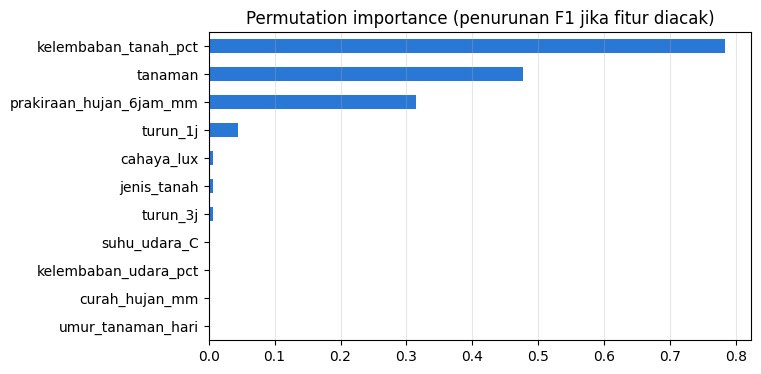

In [28]:
imp = permutation_importance(pipe_terbaik, val[FITUR], val[TARGET], scoring="f1", n_repeats=5, random_state=42)
pentingnya = pd.Series(imp.importances_mean, index=FITUR).sort_values()
pentingnya.plot.barh(color=BIRU, figsize=(7, 4))
plt.title("Permutation importance (penurunan F1 jika fitur diacak)"); plt.grid(axis="x", alpha=0.3); plt.show()

**Cara kerja *permutation importance*:** isi satu kolom diacak, lalu dilihat seberapa jauh F1 turun. Kalau turunnya banyak, berarti fitur itu penting.
Hasil yang diharapkan: kelembapan tanah, tanaman, dan prakiraan hujan berada di urutan teratas, sesuai dengan logika agronom.

## 11. Simpan model untuk aplikasi web

In [29]:
paket = {
    "model": pipe_terbaik,
    "threshold": THRESHOLD,
    "fitur": FITUR,
    "aturan": ATURAN,          # dipakai untuk menyusun "alasan" di aplikasi
}
joblib.dump(paket, "model_irigasi.joblib")
print("Tersimpan: model_irigasi.joblib → download dari panel 📁 di kiri")

Tersimpan: model_irigasi.joblib → download dari panel 📁 di kiri


## 12. 🔒 Membuka data TEST, SATU KALI
**Jalankan sel ini hanya setelah semua keputusan final** (model, fitur, threshold, pembersihan).
Setelah melihat hasilnya, **jangan kembali mengubah apa pun**. Laporkan angkanya apa adanya.

In [30]:
print("=== Data TEST (15–31 Okt, jam 05–17) ===")
tebak_test_baseline = (test["kelembaban_tanah_pct"] < 35).astype(int)
batas_test = test["tanaman"].map(ATURAN)
tebak_test_aturan = ((test["kelembaban_tanah_pct"] < batas_test) & (test["prakiraan_hujan_6jam_mm"] < ATURAN["hujan"])).astype(int)
tebak_test_model = (pipe_terbaik.predict_proba(test[FITUR])[:, 1] >= THRESHOLD).astype(int)

nilai("Baseline (kelembapan < 35)", test[TARGET], tebak_test_baseline)
nilai("Aturan pintar", test[TARGET], tebak_test_aturan)
nilai(f"Gradient Boosting (thr={THRESHOLD:.2f})", test[TARGET], tebak_test_model)
print()
tampil_cm("MODEL di TEST", test[TARGET], tebak_test_model)

=== Data TEST (15–31 Okt, jam 05–17) ===
Baseline (kelembapan < 35)              F1 = 0.306   Precision = 0.267   Recall = 0.357
Aturan pintar                           F1 = 0.754   Precision = 0.927   Recall = 0.636
Gradient Boosting (thr=0.45)            F1 = 0.754   Precision = 0.927   Recall = 0.636

MODEL di TEST
   Benar menyuruh siram (TP)          : 89
   Siram padahal tak perlu (FP) 💧🪣  : 7  → air terbuang / akar bisa busuk
   Telat/lupa siram (FN) 🥀           : 51  → tanaman stres
   Benar tidak menyuruh (TN)          : 3309



In [31]:
import sklearn; print(sklearn.__version__)

1.6.1


In [32]:
# ===== Membuat metadata.json (catatan versi, fitur, threshold, dan metrik) =====
# Sel ini TIDAK mengubah model. Ia hanya mencatat hasil yang sudah ada ke sebuah file.
import json, platform, datetime, sklearn

def ringkas(y, pred):
    return {"f1": round(float(f1_score(y, pred)), 3),
            "precision": round(float(precision_score(y, pred)), 3),
            "recall": round(float(recall_score(y, pred)), 3)}

def tiga_metode(bag):
    batas = bag["tanaman"].map(ATURAN)
    return {
        "baseline": ringkas(bag[TARGET], (bag["kelembaban_tanah_pct"] < 35).astype(int)),
        "aturan": ringkas(bag[TARGET], ((bag["kelembaban_tanah_pct"] < batas)
                                        & (bag["prakiraan_hujan_6jam_mm"] < ATURAN["hujan"])).astype(int)),
        "model": ringkas(bag[TARGET], (pipe_terbaik.predict_proba(bag[FITUR])[:, 1] >= THRESHOLD).astype(int)),
    }

metadata = {
    "nama_model": "Gradient Boosting (HistGradientBoostingClassifier)",
    "file_model": "model_irigasi.joblib",
    "dibuat": datetime.date.today().isoformat(),
    "versi": {"python": platform.python_version(), "scikit_learn": sklearn.__version__, "pandas": pd.__version__},
    "target": TARGET,
    "fitur": FITUR,
    "threshold": round(float(THRESHOLD), 2),
    "aturan_alasan": ATURAN,
    "pembagian_data": {
        "train": "1 Agustus – 30 September 2025",
        "validation": "1 – 14 Oktober 2025",
        "test": "15 – 31 Oktober 2025",
        "catatan": "Hanya jam 05–17 (jam kerja agronom) dan pembacaan sensor yang normal",
    },
    "metrik": {"validation": tiga_metode(val), "test": tiga_metode(test)},
}

with open("metadata.json", "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2, ensure_ascii=False)
print(json.dumps(metadata["metrik"], indent=2))
print("Tersimpan: metadata.json → download dari panel file di kiri")

{
  "validation": {
    "baseline": {
      "f1": 0.346,
      "precision": 0.276,
      "recall": 0.463
    },
    "aturan": {
      "f1": 0.822,
      "precision": 0.946,
      "recall": 0.727
    },
    "model": {
      "f1": 0.858,
      "precision": 0.959,
      "recall": 0.777
    }
  },
  "test": {
    "baseline": {
      "f1": 0.306,
      "precision": 0.267,
      "recall": 0.357
    },
    "aturan": {
      "f1": 0.754,
      "precision": 0.927,
      "recall": 0.636
    },
    "model": {
      "f1": 0.754,
      "precision": 0.927,
      "recall": 0.636
    }
  }
}
Tersimpan: metadata.json → download dari panel file di kiri
